In [139]:
import sys
sys.path.append("..")

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import copy
import matplotlib.pyplot as plt

from src.data_cleaning import load_data
from src.models import create_logistic_regression, create_random_forest_search, MLP
from src.evaluation import (
    evaluate_model,
    plot_confusion_matrix,
    plot_precision_recall_curve,
    compare_models,
    plot_precision_recall_comparison
)

In [140]:
RANDOM_STATE = 40

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

### Logistic Regression

In [141]:
model_reg = create_logistic_regression(RANDOM_STATE)

model_reg.fit(X_train, y_train)

y_pred_logreg = model_reg.predict(X_test)
y_proba_logreg = model_reg.predict_proba(X_test)

loss_logreg = sklearn.metrics.log_loss(y_test, y_proba_logreg)

logreg_metrics = evaluate_model(
    y_test,
    y_pred_logreg,
    y_proba_logreg[:, 1],
    loss=loss_logreg
)

c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


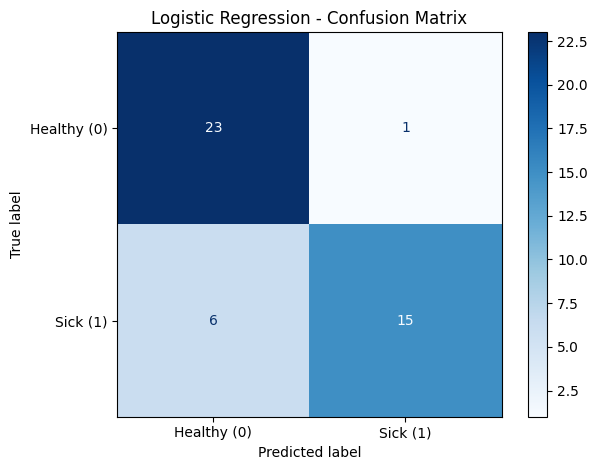

In [142]:
plot_confusion_matrix(
    y_test,
    y_pred_logreg,
    "Logistic Regression"
)

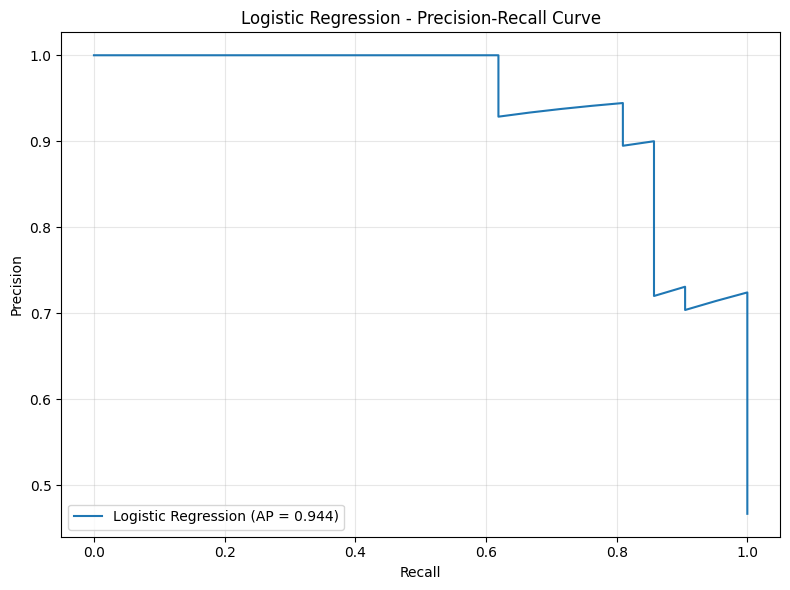

In [143]:
logreg_curve = plot_precision_recall_curve(
    y_test,
    y_proba_logreg[:, 1],
    "Logistic Regression"
)

### Random Forest

In [144]:
grid = create_random_forest_search(RANDOM_STATE)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

y_pred_rf = best_model.predict(X_test)
y_proba_rf = best_model.predict_proba(X_test)

loss_rf = sklearn.metrics.log_loss(y_test, y_proba_rf)

rf_metrics = evaluate_model(
    y_test,
    y_pred_rf,
    y_proba_rf[:, 1],
    loss=loss_rf
)

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
0.8545876887340302



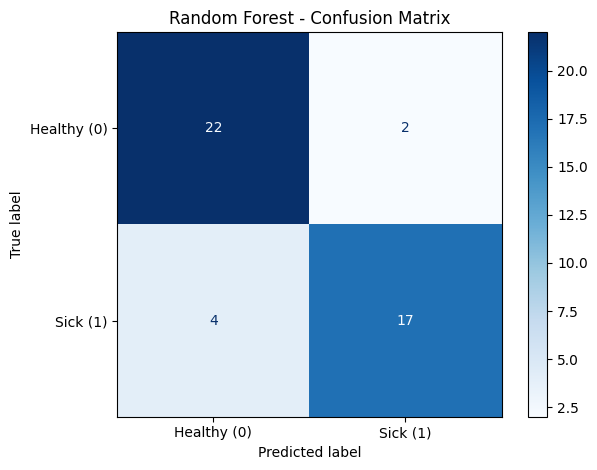

In [145]:
plot_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random Forest"
)

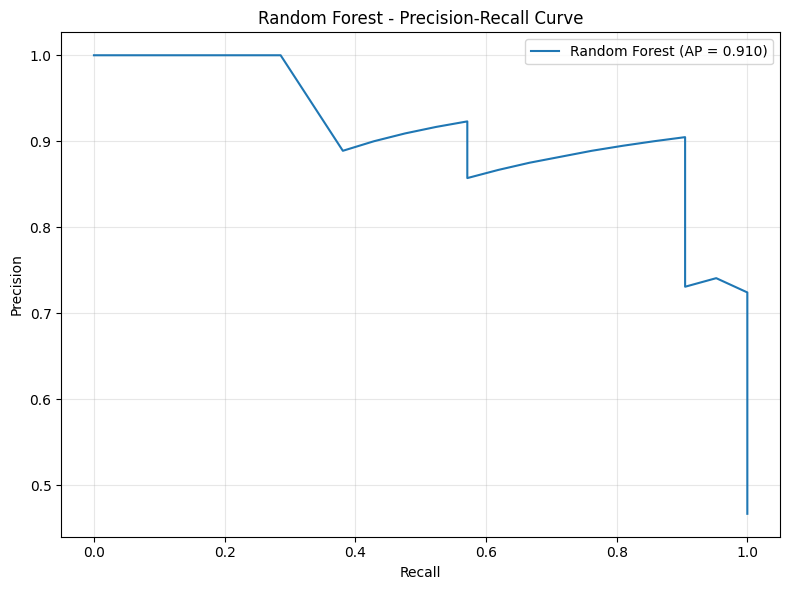

In [146]:
rf_curve = plot_precision_recall_curve(
    y_test,
    y_proba_rf[:, 1],
    "Random Forest"
)

### Multi-Layer Perceptron (MLP)

In [147]:
BATCH_SIZE = 16
DROPOUT = 0.3
LEARNING_RATE = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
EPOCHS = 2000


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [148]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [149]:
mlp_model = MLP(in_features, out_features, DROPOUT).to(device)
optimizer = torch.optim.SGD(params=mlp_model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

def accuracy(yt_pred, yt_true):
    return (yt_pred == yt_true).float().mean()

In [150]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS+1):

    mlp_model.train()
    mean_train_loss = 0
    mean_train_acc = 0
    
    for Xt_batch, yt_batch in train_loader :

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += train_loss.item() * Xt_batch.shape[0]/Xt_train.shape[0]

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        train_acc = accuracy(yt_pred_class, yt_batch)
        mean_train_acc += train_acc.item() * Xt_batch.shape[0]/Xt_train.shape[0]


        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()


    mlp_model.eval()

    with torch.no_grad() :
        
        yt_pred = mlp_model(Xt_val)

        val_loss = criterion(yt_pred, yt_val).item()

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        val_acc = accuracy(yt_pred_class, yt_val).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_accuracy = val_acc
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    
    if epoch%100 == 0:

        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(mean_train_acc)
        val_accuracies.append(val_acc)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f} | Train accuracy: {mean_train_acc:.2%}")
        print(f"Val loss: {val_loss:.4f} | Val accuracy: {val_acc:.2%}")
        print("")


mlp_model.load_state_dict(best_weights)
print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_val_accuracy:.2%}")

Epoch: 100
Train loss: 0.6726 | Train accuracy: 60.39%
Val loss: 0.6520 | Val accuracy: 64.44%

Epoch: 200
Train loss: 0.6154 | Train accuracy: 71.50%
Val loss: 0.6058 | Val accuracy: 82.22%

Epoch: 300
Train loss: 0.5662 | Train accuracy: 76.81%
Val loss: 0.5488 | Val accuracy: 88.89%

Epoch: 400
Train loss: 0.5016 | Train accuracy: 80.19%
Val loss: 0.4827 | Val accuracy: 86.67%

Epoch: 500
Train loss: 0.4889 | Train accuracy: 81.64%
Val loss: 0.4270 | Val accuracy: 88.89%

Epoch: 600
Train loss: 0.4816 | Train accuracy: 78.74%
Val loss: 0.3905 | Val accuracy: 88.89%

Epoch: 700
Train loss: 0.4423 | Train accuracy: 84.06%
Val loss: 0.3684 | Val accuracy: 88.89%

Epoch: 800
Train loss: 0.4322 | Train accuracy: 83.09%
Val loss: 0.3550 | Val accuracy: 88.89%

Epoch: 900
Train loss: 0.4056 | Train accuracy: 84.54%
Val loss: 0.3470 | Val accuracy: 86.67%

Epoch: 1000
Train loss: 0.4355 | Train accuracy: 83.57%
Val loss: 0.3414 | Val accuracy: 86.67%

Epoch: 1100
Train loss: 0.3838 | Train 

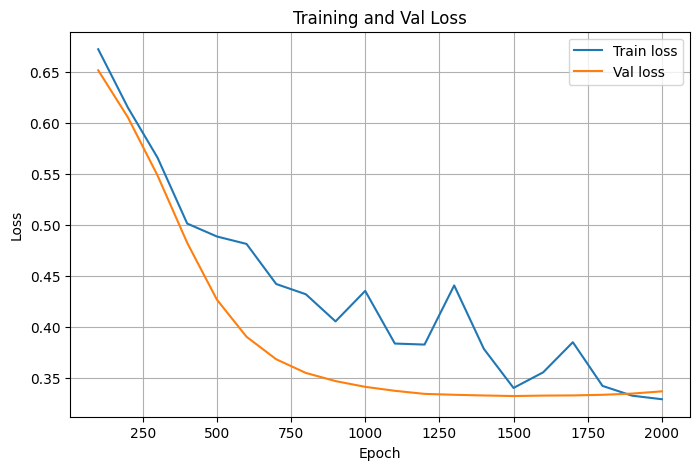

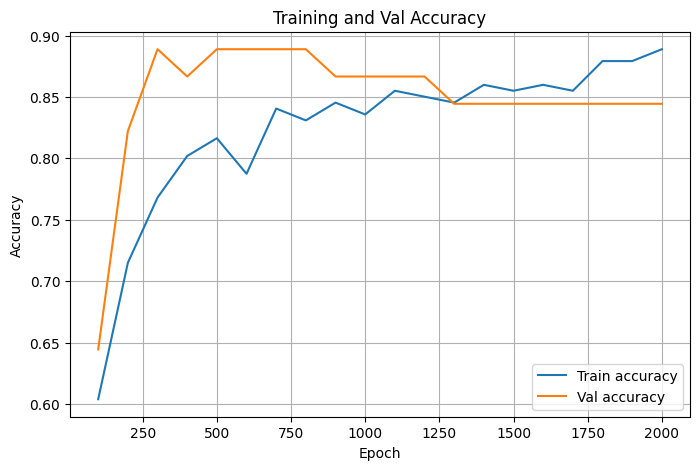

In [151]:
epochs = range(100, EPOCHS + 1, 100)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Val Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graphe 2 : Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, val_accuracies, label="Val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Val Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [152]:
mlp_model.eval()

with torch.no_grad():
    yt_pred = mlp_model(Xt_test)
    mlp_loss = criterion(yt_pred, yt_test).item()
    yt_pred_class = torch.argmax(yt_pred, dim=1)

    y_true_mlp = yt_test.cpu().numpy()
    y_pred_mlp = yt_pred_class.cpu().numpy()
    y_proba_mlp = torch.softmax(yt_pred, dim=1)[:, 1].cpu().numpy()

mlp_metrics = evaluate_model(
    y_true_mlp,
    y_pred_mlp,
    y_proba_mlp,
    loss=mlp_loss
)

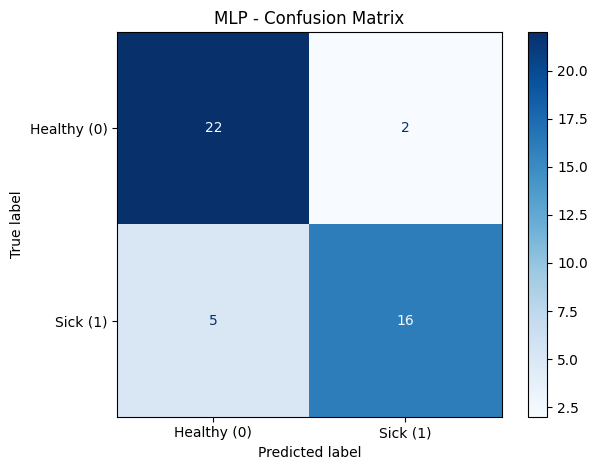

In [153]:
plot_confusion_matrix(
    yt_test.cpu().numpy(),
    yt_pred_class.cpu().numpy(),
    "MLP"
)

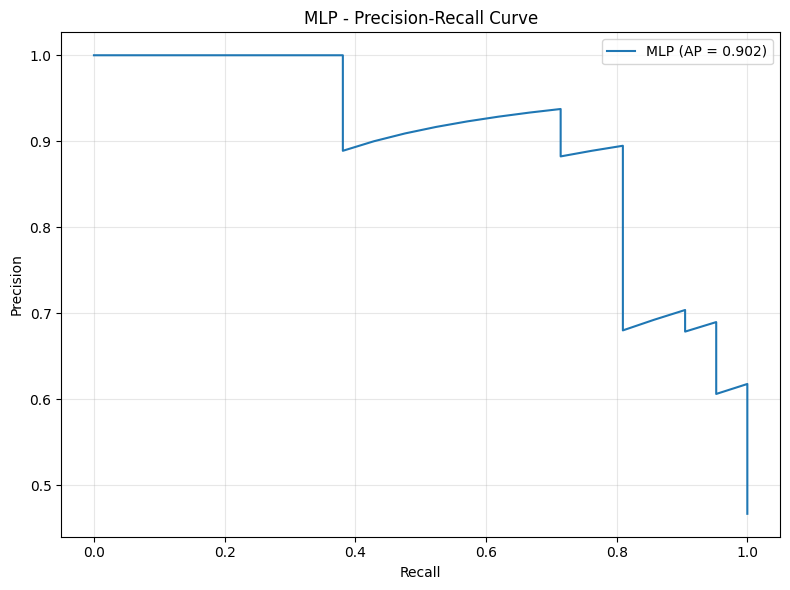

In [154]:
mlp_curve = plot_precision_recall_curve(
    y_true_mlp,
    y_proba_mlp,
    "MLP"
)

### Model Comparison Overview

In [155]:
model_metrics = {
    "Logistic Regression": logreg_metrics,
    "Random Forest": rf_metrics,
    "MLP": mlp_metrics
}

results = compare_models(model_metrics)
display(results.round(4))

,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,
Logistic Regression,0.4783,0.8444,0.9375,0.7143,0.8108,0.9441
Random Forest,0.3738,0.8667,0.8947,0.8095,0.8500,0.9100
MLP,0.3847,0.8444,0.8889,0.7619,0.8205,0.9017


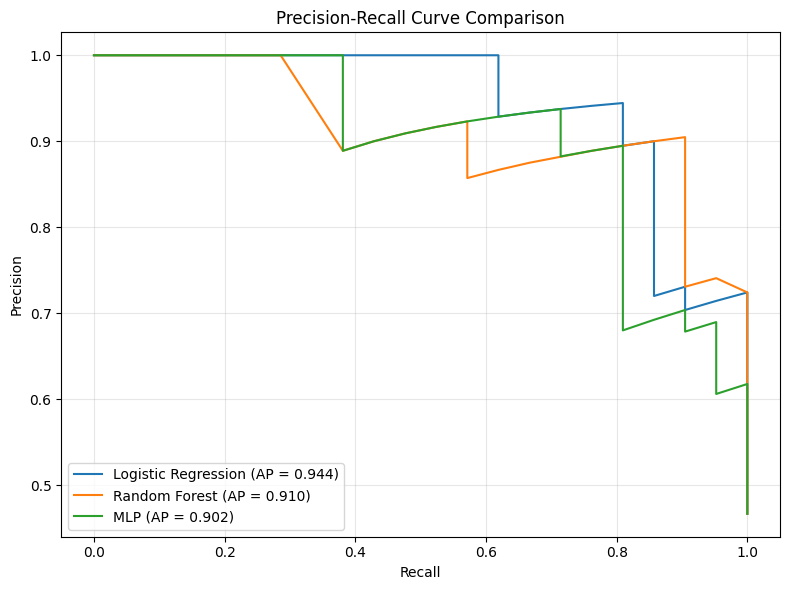

In [156]:
curves = {
    "Logistic Regression": logreg_curve,
    "Random Forest": rf_curve,
    "MLP": mlp_curve
}

plot_precision_recall_comparison(curves)